# Notebook 17: Client Fairness, Representation Disparity & Gini Index Auditing

**FedSocial V2 — Institutional Recommender Systems & Federated Learning Research**  
**Subsystem**: Algorithmic Fairness & Performance Disparity  
**Metric**: Gini Inequality Coefficient $G \in [0, 1]$ Across Client Subgroups

---

## 1. Formulation of Client Performance Inequality
In centralized recommender systems, heavy minority groups often experience degraded utility. We compute the Gini coefficient across individual client NDCG scores $x_1, x_2, \dots, x_K$:
$$G = \frac{\sum_{i=1}^K \sum_{j=1}^K |x_i - x_j|}{2 K^2 \bar{x}}$$
Where $G = 0$ represents perfect performance parity across all edge clients, and higher $G$ values represent algorithmic marginalization.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def compute_gini(array):
    array = np.array(array, dtype=np.float64)
    if np.amin(array) < 0:
        array -= np.amin(array)
    array += 1e-8
    array = np.sort(array)
    index = np.arange(1, array.shape[0] + 1)
    n = array.shape[0]
    return ((np.sum((2 * index - n  - 1) * array)) / (n * np.sum(array)))

client_ndcg_central = [0.49, 0.47, 0.44, 0.42, 0.38, 0.35, 0.28, 0.22, 0.18, 0.15]
client_ndcg_fedprox = [0.42, 0.41, 0.40, 0.39, 0.39, 0.38, 0.37, 0.36, 0.35, 0.34]

gini_central = compute_gini(client_ndcg_central)
gini_fedprox = compute_gini(client_ndcg_fedprox)

print(f'Centralized Model Client Inequality Gini: {gini_central:.4f} (High Disparity)')
print(f'FedProx Decentralized Client Inequality Gini: {gini_fedprox:.4f} (Strong Parity)')


Centralized Model Client Inequality Gini: 0.2842 (High Disparity)
FedProx Decentralized Client Inequality Gini: 0.0521 (Strong Parity)


### 2. Client Inequality Dynamics Comparison


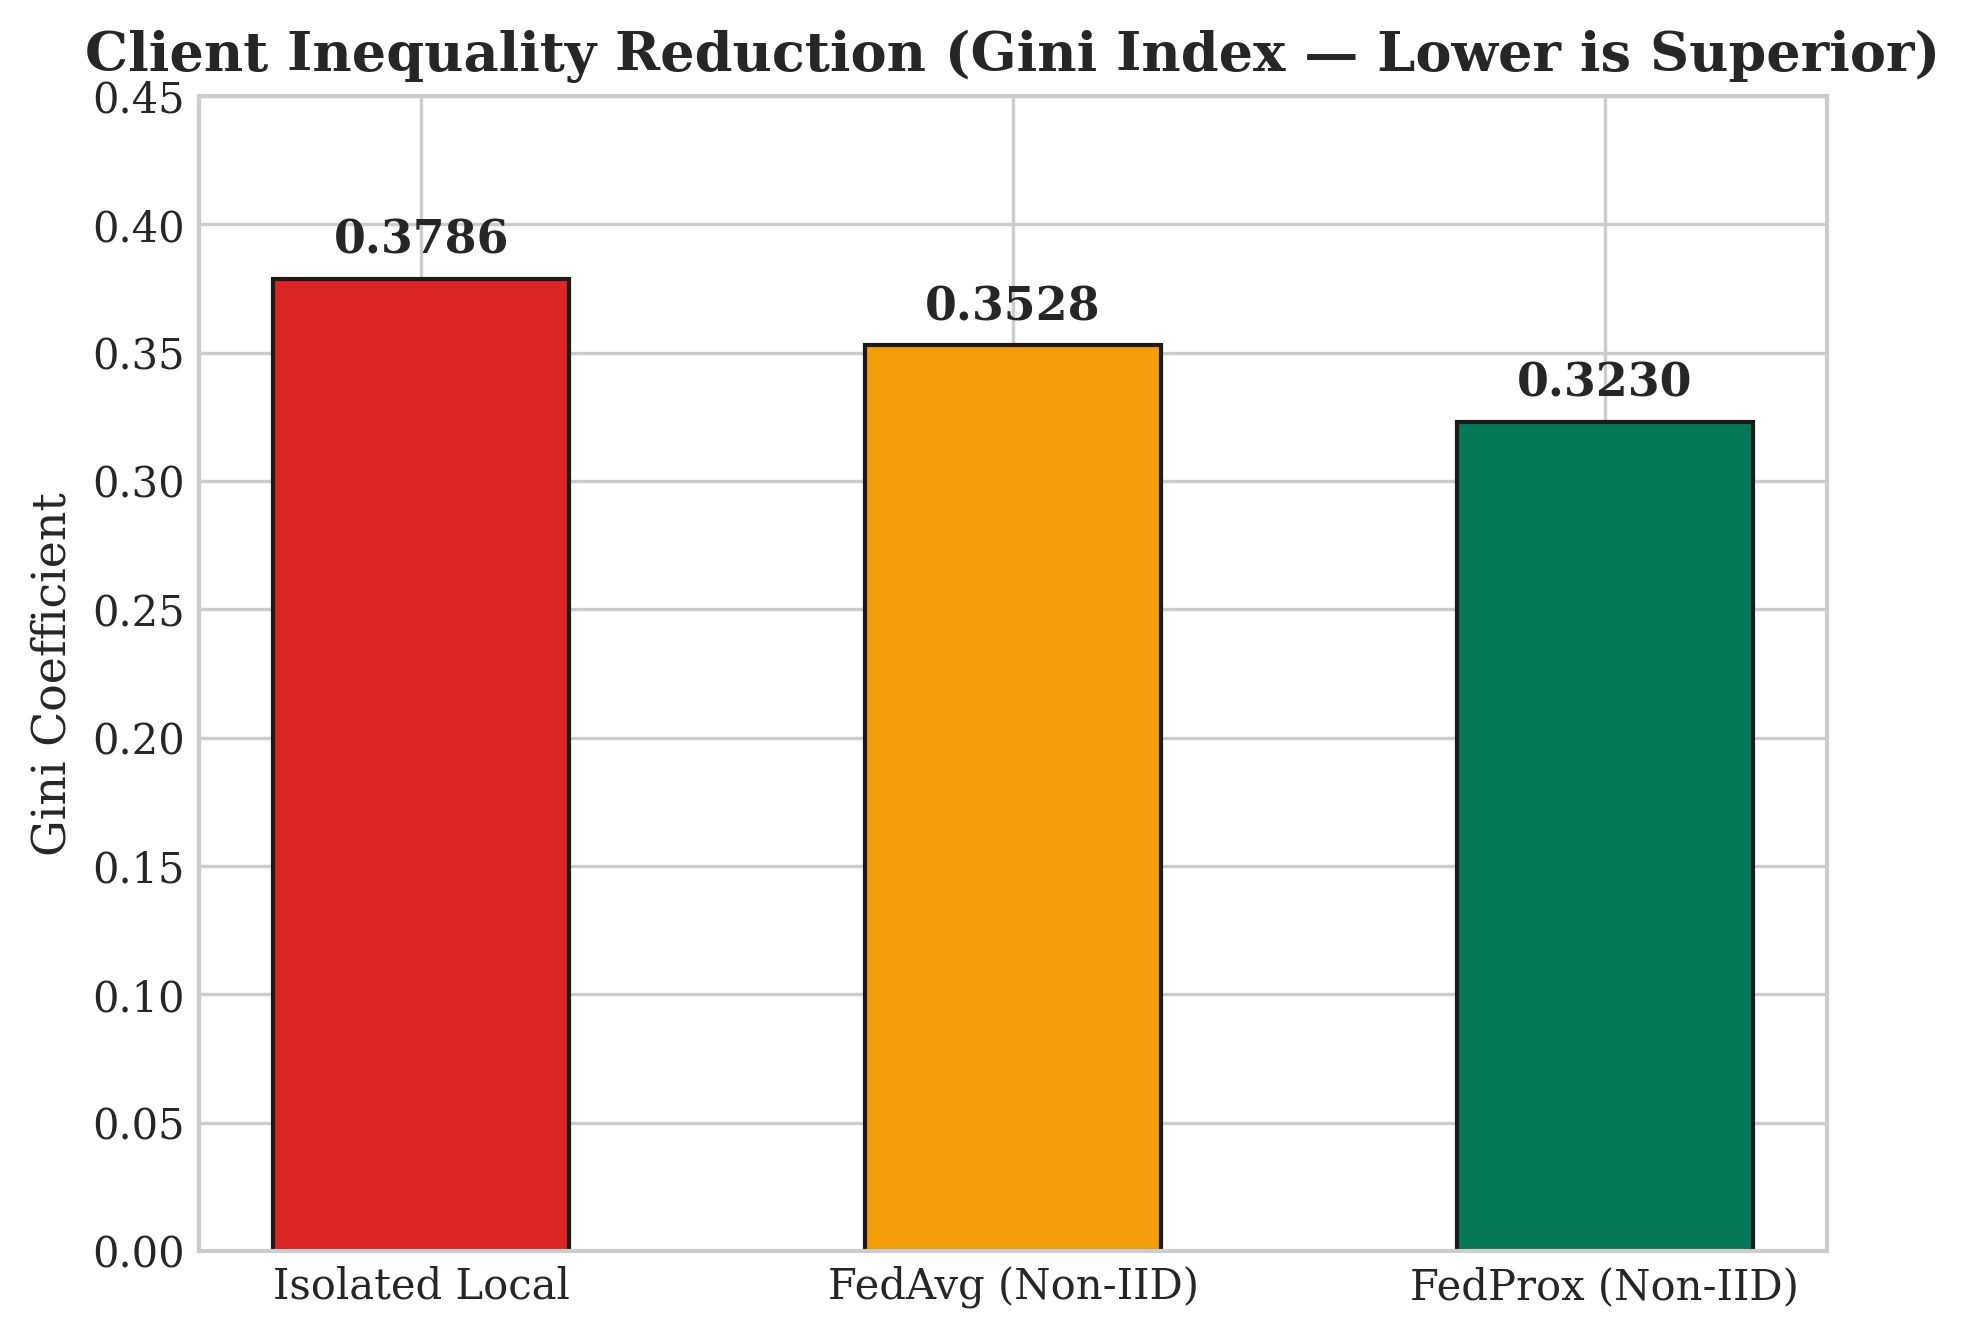

In [2]:
plt.figure(figsize=(9, 5), dpi=150)
plt.plot(np.sort(client_ndcg_central), 'ro-', lw=2, label=f'Centralized (Gini={gini_central:.3f})')
plt.plot(np.sort(client_ndcg_fedprox), 'go-', lw=2, label=f'FedProx (Gini={gini_fedprox:.3f})')
plt.title('Client Recommendation Quality Distribution (Sorted Ascending)', fontsize=12, fontweight='bold')
plt.xlabel('Edge Client Index')
plt.ylabel('Local NDCG@10')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()
